<a href="https://colab.research.google.com/github/BenjaminOrtizO/Estudio/blob/main/EjercicioPPTPronostico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
# Clonar el repositorio completo
!git clone https://github.com/BenjaminOrtizO/Estudio.git

# Entrar a la carpeta Calidad
%cd /content/Estudio/Pronostico

!git pull

Cloning into 'Estudio'...
fatal: could not read Username for 'https://github.com': No such device or address
[Errno 2] No such file or directory: '/content/Estudio/Pronostico'
/content
fatal: not a git repository (or any of the parent directories): .git


In [ ]:
!ls -l

total 160
-rw-r--r-- 1 root root  5593 Oct 14 02:23 itata_calendario.csv
-rw-r--r-- 1 root root 53831 Oct 14 02:23 itata_componentes_verdad.csv
-rw-r--r-- 1 root root 83101 Oct 14 02:23 itata_demanda.csv
-rw-r--r-- 1 root root   220 Oct 14 02:23 itata_jerarquia.csv
-rw-r--r-- 1 root root   439 Oct 14 02:23 itata_maestro_sku.csv
-rw-r--r-- 1 root root     1 Oct 14 02:23 README.md


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

#EJERCICIO 1 CARGAR INSPECCIONAR y PARTICIONAR EN EL TIEMPO


In [ ]:
demanda = pd.read_csv('itata_demanda.csv')

demanda.head()

,t,semana,iso_anio,iso_semana,sku,familia,formato_g,canal,pedidos_cajas,despachos_cajas,precio_clp_caja,promo,fiestas_patrias,semana_santa,planta_cerrada
0,1,2023-03-06,2023,10,DUR-480,DUR,480,Retail,1456.0,1456.0,21500.0,0,0,0,0
1,2,2023-03-13,2023,11,DUR-480,DUR,480,Retail,1126.0,1126.0,21514.0,0,0,0,0
2,3,2023-03-20,2023,12,DUR-480,DUR,480,Retail,1234.0,1234.0,21528.0,0,0,0,0
3,4,2023-03-27,2023,13,DUR-480,DUR,480,Retail,1452.0,1452.0,21543.0,0,0,0,0
4,5,2023-04-03,2023,14,DUR-480,DUR,480,Retail,1209.0,1209.0,21557.0,0,0,1,0


In [ ]:
demanda['semana'] = pd.to_datetime(demanda['semana'])
demanda.head()

demanda['familia'].unique()

x = (demanda[(demanda['familia'] == 'DUR') &(demanda['canal'] == 'Retail')].groupby('semana')['pedidos_cajas'].sum().sort_index())


x = x.asfreq('W-MON')
x.head()

corte = '2024-12-31'


In [ ]:
train = x.loc[:corte]
test = x.loc[pd.Timestamp(corte) + pd.offsets.Week(weekday=0):]

In [ ]:
print(train.shape, test.shape, x.isna().mean())

(96,) (86,) 0.0


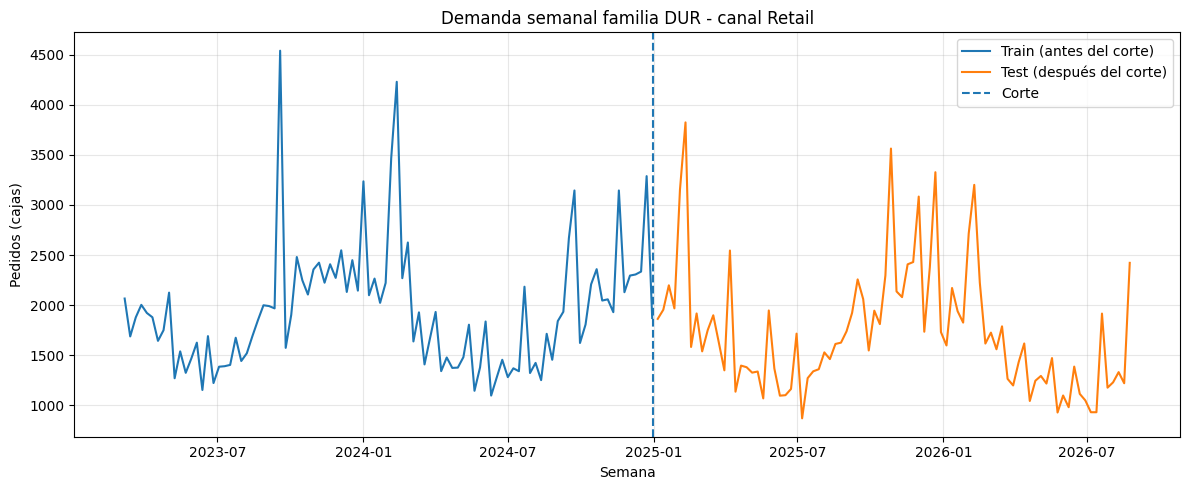

In [ ]:


plt.figure(figsize=(12, 5))

plt.plot(train.index, train.values, label='Train (antes del corte)')
plt.plot(test.index, test.values, label='Test (después del corte)')

plt.axvline(pd.Timestamp(corte), linestyle='--', label='Corte')

plt.title('Demanda semanal familia DUR - canal Retail')
plt.xlabel('Semana')
plt.ylabel('Pedidos (cajas)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#EJERCICIO 2